In [1]:
import jax
import os

jax.config.update('jax_platform_name', 'cpu')

# Avoid OOM errors
# os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"]=".33"
# # os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"]="false"
print(f"JAX backend: {jax.default_backend()}")

JAX backend: cpu


In [2]:
import sys
sys.path.append("../")

# %load_ext autoreload
# %autoreload 2

import pulse_simulator as ps

/home/andy/.cache/pypoetry/virtualenvs/pulse-simulator-0UjnMsVt-py3.10/lib/python3.10/site-packages/qiskit_dynamics/dispatch/backends/jax.py:34: UserWarning: The functionality in the perturbation module of Qiskit Dynamics requires a JAX version <= 0.4.6, due to a bug in JAX versions > 0.4.6. For versions 0.4.4, 0.4.5, and 0.4.6, using the perturbation module functionality requires setting os.environ['JAX_JIT_PJIT_API_MERGE'] = '0' before importing JAX or Dynamics.
  warnings.warn(


In [3]:
from copy import deepcopy
from datetime import datetime
import functools
import itertools
import logging
import numpy as np
import pickle as pkl
import qiskit as qk
from qiskit import pulse
import qiskit_aer
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d
import qutip as qt
import re 
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm
from tqdm import tqdm
import warnings

import matplotlib.pyplot as plt
tab20 = plt.get_cmap("tab20")

In [4]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

backend = qk_fp.FakeManila()
dt = backend.configuration().dt * ns
desired_1qb_duration = 225  # dt
desired_2qb_duration = 225 * 4  # dt

# Gate time in SI units (granularity restriction)
duration_1qb = ps.qiskit_closest_multiple_of_16(desired_1qb_duration * dt / ns, backend)
duration_2qb = ps.qiskit_closest_multiple_of_16(desired_2qb_duration * dt / ns, backend)

# Option 1: Qiskit dynamics

First, make a schedule that simualtes an X gate (could also just initialize in excited state).

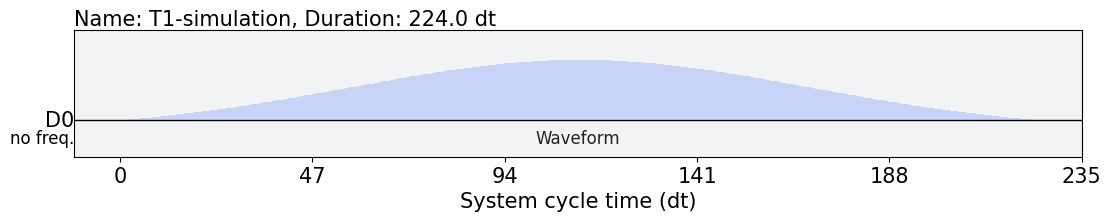

In [5]:
registers = [0]

# Load an X gate  type
default_gates = {"X1": ps.gaussian_envelope(duration_1qb, dt=dt, angle=np.pi / 2)}

my_moments = [{0: "X1"}]

my_schedule = ps.build_pulse_schedule(
    my_moments,
    default_gates,
    _,
    registers,
    backend,
    dt=dt,
    name="T1-simulation",
)

my_schedule.draw()

In [6]:
# Set registers above with circuit
# The rest is automatic
# ===================== 

# NOTE: If the Rabi rates are True, you have to calibrate!
cvars = ps.backend_simulation_vars(backend, rabi=False, units=Units)

# Change T1 and T2 to match Eagle processors like Sherbrooke
for k, v in cvars.items():
    if "t1" in k:
        t1 = 250 / μs * ns
        cvars[k] = t1
    if "t2" in k:
        # NOTE: Turn off to isolate T1!
        cvars[k] = None # 150 / μs * ns

# Carrier frequencies of each control line
# NOTE: We won't use carriers in this example
carriers = ps.backend_carriers(backend, cvars)

# Partially compile model functions with parameters
# -----
H_rx = functools.partial(
    ps.rx_model,
    registers=registers,
    backend=backend,
    variables=cvars,
    rotating_frame=True,
)

H_rz = functools.partial(
    ps.rz_model,
    registers=registers,
    backend=backend,
)

A_decay = functools.partial(ps.qubit_decay_model, registers=registers, variables=cvars)

# Create a system model
# -----
H_drift = 0.0
Hs_control = []
Hs_channels = []
As_static = []
for qubit in registers:
    # Single qubit terms
    Hj_drift, Hjs_control, Hjs_channel = H_rx(qubit)
    Hj_phase, Hj_phase_ch = H_rz(qubit)
    Ajs_static = A_decay(qubit)

    H_drift += Hj_drift
    Hs_control += Hjs_control + [Hj_phase]
    Hs_channels += Hjs_channel + [Hj_phase_ch]
    As_static += Ajs_static

# Some models may repeat control channels
# -----
# NOTE: This actually really matters! Repeat channels mess things up.
Hs_channels, indices = np.unique(Hs_channels, return_index=True)
Hs_control = [Hs_control[i] for i in indices]

# For RWA / Rotating frame
# Recall: We won't use carriers in this example
# -----
registered_carriers = {c: 0 for c in Hs_channels}
cutoff_freq = None

In [7]:
solver = qk_d.Solver(
    static_hamiltonian=None,
    hamiltonian_operators=Hs_control,
    hamiltonian_channels=Hs_channels,
    static_dissipators=As_static,
    rotating_frame=None,
    rwa_cutoff_freq=None,
    channel_carrier_freqs=registered_carriers,
    dt=dt
)

In [8]:
# Data evaluation after the gate was applied
t_eval = np.linspace(my_schedule.duration * dt, 250 / μs * ns, 25)

# Wait time after the gate was applied
t_wait = my_schedule.duration * dt + np.linspace(0, 250 / μs * ns, 100)

We will simulate for two types of initial state. It gives us different answers.

In [9]:
# Two inital states
# NOTE: We applied a gate using the schedule, so we want to start from the ground state
y0_dict = {
    "SuperOp": ps.qiskit_identity_operator(len(registers), open=True),
    "DensityMatrix": ps.qiskit_ground_state(len(registers), open=True)
}
res = {}
fids = {}
for label, y0 in y0_dict.items():
    if isinstance(y0, qk.quantum_info.SuperOp):
        print("Using dense vectorized mode for super operator...")
        solver.model.evaluation_mode = "dense_vectorized"
    elif isinstance(y0, qk.quantum_info.DensityMatrix):
        print("Using dense mode for density matrix...")
        solver.model.evaluation_mode = "dense"
    else:
        raise ValueError(f"Unimplemented initial state type {type(y0)}")

    res[label] = solver.solve(
        t_span=[0.0, t_eval[-1]],
        t_eval=t_eval,
        y0=y0,
        signals=my_schedule,
        atol=1e-9,
        rtol=1e-9,
        method="jax_odeint",
    )

    if isinstance(y0, qk.quantum_info.SuperOp):
        target = qk.quantum_info.Operator([[0, 1], [1, 0]])
        # fids[label] = [ps.quantum_info.process_fidelity(y, target) for y in res[label].y]

        # NOTE: You have to evolve the initial state to the target state to get the fidelity
        # You cannot just compare the unitaries. You will be off.
        rho0 = ps.qiskit_ground_state(len(registers), open=True)
        rhof = rho0.evolve(target)
        fids[label] = [ps.quantum_info.state_fidelity(rho0.evolve(y), rhof) for y in res[label].y]
        
    elif isinstance(y0, qk.quantum_info.DensityMatrix):
        target = qk.quantum_info.DensityMatrix([[0, 0], [0, 1]])
        fids[label] = [ps.quantum_info.state_fidelity(y, target) for y in res[label].y]
    else:
        raise ValueError(f"Unimplemented initial state type {type(y0)}")

Using dense vectorized mode for super operator...
Using dense mode for density matrix...


Text(0.0, 1.0, 'Qiskit')

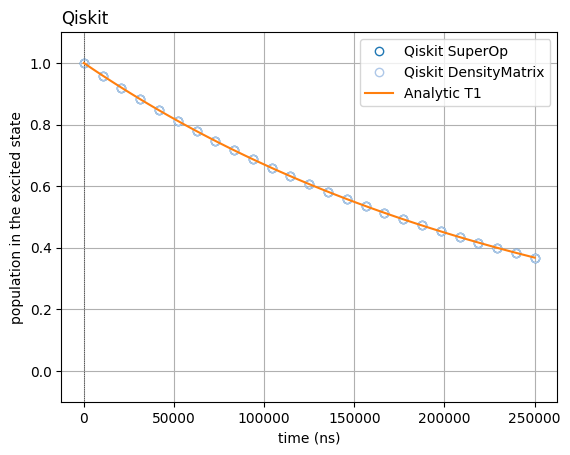

In [10]:
fig, ax = plt.subplots()

for i, (l, f) in enumerate(fids.items()):
    ax.plot(t_eval, f, label=f"Qiskit {l}", c=tab20(i), marker="o", markerfacecolor='None', ls='')

ax.axvline(my_schedule.duration * dt, lw=0.5, color="k", linestyle=":")

# ax.plot(t_wait, np.exp(-t_wait / 2 / t1), ls="-", label="Analytic 2*T1", c=tab20(4))
ax.plot(t_wait, np.exp(-t_wait / t1), ls="-", label="Analytic T1", c=tab20(2))


ax.legend()
ax.set_ylabel("population in the excited state")
ax.set_xlabel("time (ns)")
ax.set_ylim(-0.1, 1.1)
ax.grid(True)
ax.set_title("Qiskit", loc="left")

# Option 2: Qutip mesovle

In [11]:
# Check that the Linbdlad operator we plan to use to the get T1 is the one we'd expect
qt.Qobj(As_static[0].data)  == qt.destroy(2) / np.sqrt(t1)

True

In [12]:
# Idle dynamics
H_qutip =  [
    qt.Qobj(H_drift.data),
    [qt.Qobj(Hs_control[0].data), "0"]
]

# Excited state
rho0 = qt.Qobj([[0, 0], [0, 1]])

# Collapse operators... are off by a factor of sqrt(2) for some reason
c_ops = [[qt.Qobj(A.data), '1'] for A in As_static]

# c_ops = [[qt.Qobj(A.data), 'sqrt(2)'] for A in As_static]
a = qt.destroy(2)

res_qt = qt.mesolve(
    H=H_qutip,
    rho0=rho0,
    tlist=t_eval,
    c_ops=c_ops,
    e_ops=[a.dag() * a],
)

fids_qt = res_qt.expect[0]
# fids_qt = [qt.fidelity(s, rho0) for s in res_qt.states]

Qutip uses a vectorized Lindblad simulator no matter what. Therefore, we expect a match with Qiskit's SuperOp result.

Text(0.0, 1.0, 'Qutip')

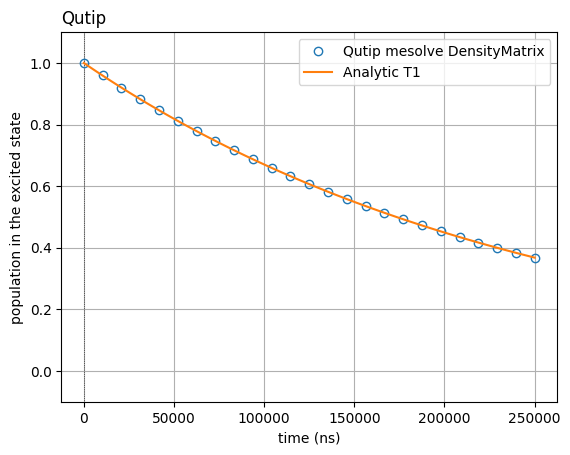

In [13]:
fig, ax = plt.subplots()
ax.axvline(my_schedule.duration * dt, lw=0.5, color="k", linestyle=":")

ax.plot(t_eval, fids_qt, label="Qutip mesolve DensityMatrix", marker="o", markerfacecolor='None', ls='', c=tab20(0))

# ax.plot(t_wait, np.exp(-t_wait / 2 / t1), ls="-", label="Analytic 2*T1", c=tab20(4))
ax.plot(t_wait, np.exp(-t_wait / t1), ls="-", label="Analytic T1", c=tab20(2))

ax.legend()
ax.set_ylabel("population in the excited state")
ax.set_xlabel("time (ns)")
ax.set_ylim(-0.1, 1.1)
ax.grid()
ax.set_title("Qutip", loc="left")

# Option 3: Qutip Processor

I'm not sure how Qutip's processor simulates. If it doesn't use a vectorized equation, then we would have a consistent hypothesis (that vectorization is the reason for the mismatch).

In [14]:
from qutip.qip.device import Processor
from qutip.qip.pulse import Pulse

In [15]:
a = qt.destroy(2)
psi0 = qt.basis(2,1)

# creat a dummpy pulse that has no Hamiltonian, but only a tlist.
processor = Processor(1, t1=t1, t2=None)
processor.add_pulse(Pulse(None, None, tlist=t_eval, coeff=False))

# No collapse operators in processor, just manual ones
evo, c_ops_processor = processor.get_qobjevo(noisy=False)
print(c_ops_processor, c_ops)

# =====

result = processor.run_state(init_state=psi0, e_ops=[a.dag()*a]) # noisy=False, c_ops=c_ops)

# BUG? Cannot repeat processor runs because the noise list updates
result2 = processor.run_state(init_state=psi0, e_ops=[a.dag()*a])

result3 = qt.mesolve(
    H=evo,
    rho0=psi0,
    tlist=t_eval,
    c_ops=c_ops_processor + c_ops,
    e_ops=[a.dag()*a]
)

[] [[Quantum object: dims = [[2], [2]], shape = (2, 2), type = oper, isherm = False
Qobj data =
[[0.    0.002]
 [0.    0.   ]], '1']]


Text(0.0, 1.0, 'Qutip processors')

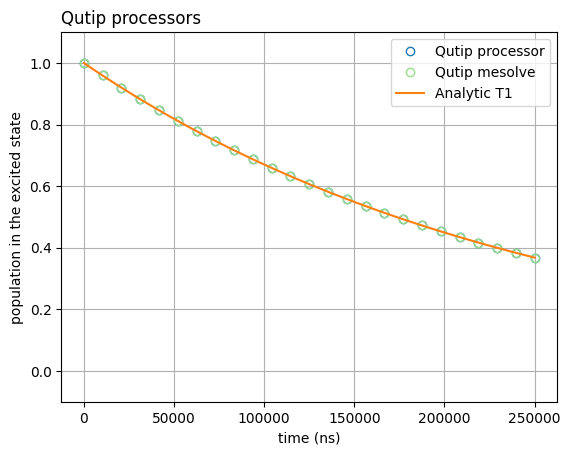

In [16]:
fig, ax = plt.subplots()
ax.plot(t_eval, result.expect[0], label="Qutip processor", marker="o", markerfacecolor='None', ls='', c=tab20(0))
# ax.plot(t_eval, result2.expect[0], label="Qutip processor, run again", marker="o", markerfacecolor='None', ls='', c=tab20(1))
ax.plot(t_eval, result3.expect[0], label="Qutip mesolve", marker="o", markerfacecolor='None', ls='', c=tab20(5))

# ax.plot(t_wait, np.exp(-t_wait / 2 / t1), ls="-", label="Analytic 2*T1", c=tab20(4))
ax.plot(t_wait, np.exp(-t_wait / t1), ls="-", label="Analytic T1", c=tab20(2))

ax.set_xlabel("t")
ax.set_ylabel("population in the excited state")
ax.set_xlabel("time (ns)")
ax.legend()
ax.set_ylim(-0.1, 1.1)
ax.grid()
ax.set_title("Qutip processors", loc="left")

## Bug for qutip processor

In [17]:
# creat a dummy pulse that has no Hamiltonian, but only a tlist.
processor = Processor(1, t1=t1, t2=None)
processor.add_pulse(Pulse(None, None, tlist=t_eval, coeff=False))

processor_before = deepcopy(processor)
pulses = deepcopy(processor.pulses)
noise = deepcopy(processor.noise)
dims = deepcopy(processor.dims)
print(noise, processor.t1)

# NOTE: The noise is added to list after run_state is called
result = processor.run_state(init_state=psi0, e_ops=[a.dag()*a])
print(processor.noise, processor.t1)

[] 250000.0
[<qutip.qip.noise.RelaxationNoise object at 0x7fded22a3a60>] 250000.0


In [18]:
noisy_pulses = qt.qip.noise.process_noise(
    pulses, 
    noise, 
    dims,
    device_noise=True
)
# Initial, Systematic noise
print(len(noisy_pulses))

# Systematic noise
noisy_pulses[1].print_info()

2
----------------------------------------------------------------------
Pulse label: systematic_noise
The pulse contains: 0 coherent noise elements and 0 Lindblad noise elements.

Ideal pulse:
{'qobj': None, 'targets': None, 'tlist': None, 'coeff': None}
----------------------------------------------------------------------


this code has side effects
```Python
    noisy_pulses = process_noise(
        pulses, self.noise, self.dims, t1=self.t1, t2=self.t2,
        device_noise=device_noise)
```

Why not this?
```Python
    noisy_pulses = process_noise(
        pulses, deepcopy(self.noise), self.dims, t1=self.t1, t2=self.t2,
        device_noise=device_noise)
```

In [19]:
c_ops = []
"""
WARNING! cannot run twice or after run_state.
> The length of the new list of noisy pulses might be longer
> because of drift Hamiltonian and device noise. They will be
> added to the end of the pulses list.
"""
noisy_pulses = processor_before.get_noisy_pulses(device_noise=True, drift=True)
for p in noisy_pulses:
    _, c_ops_new = p.get_noisy_qobjevo(dims=dims)
    c_ops += c_ops_new
c_ops

In [20]:
noisy_pulses[1].print_info()

----------------------------------------------------------------------
Pulse label: systematic_noise
The pulse contains: 0 coherent noise elements and 1 Lindblad noise elements.

Ideal pulse:
{'qobj': None, 'targets': None, 'tlist': None, 'coeff': None}

Lindblad noise:
{'qobj': Quantum object: dims = [[2], [2]], shape = (2, 2), type = oper, isherm = False
Qobj data =
[[0.    0.002]
 [0.    0.   ]], 'targets': 0, 'tlist': None, 'coeff': True}
----------------------------------------------------------------------
